In [1]:
import pandas as pd
import statsmodels.formula.api as sm
import matplotlib.pyplot as plt

In [2]:
campaigns = pd.read_csv('../data/northbound_campaigns.csv')

In [4]:
campaigns.describe()

,discount_offer,spend,impressions,clicks,conversions,revenue
count,441.000000,441.000000,4.410000e+02,441.000000,441.000000,441.000000
mean,0.287982,4515.389524,5.097811e+05,5912.539683,162.680272,14825.101134
std,0.453337,2430.783140,4.213068e+05,3767.812582,165.469346,15085.349343
min,0.000000,605.720000,4.201200e+04,936.000000,5.000000,526.370000
25%,0.000000,2730.400000,2.264550e+05,3384.000000,52.000000,4696.480000
50%,0.000000,3991.990000,3.702860e+05,4780.000000,93.000000,8691.830000
75%,1.000000,5841.170000,6.422740e+05,7328.000000,208.000000,19089.650000
max,1.000000,15587.120000,2.575538e+06,29022.000000,940.000000,90259.370000


In [5]:
campaigns['channel'].value_counts()

channel
Search     151
Social     127
Display     90
Video       73
Name: count, dtype: int64

In [6]:
search = campaigns[campaigns['channel'] == 'Search'].copy()
search.head()

,campaign_id,week_start,channel,discount_offer,spend,impressions,clicks,conversions,revenue
1,NB0002,2023-01-09,Search,0,4512.46,198756,9592,220,20834.90
5,NB0006,2023-01-16,Search,0,3063.68,131636,5579,167,16614.48
7,NB0008,2023-01-23,Search,0,3851.73,221903,9663,256,23956.14
10,NB0011,2023-01-30,Search,0,5287.11,226840,9564,273,26290.07
12,NB0013,2023-02-06,Search,0,7094.57,226455,12134,327,30421.52


In [7]:
search['impressions_k'] = search['impressions'] / 1000

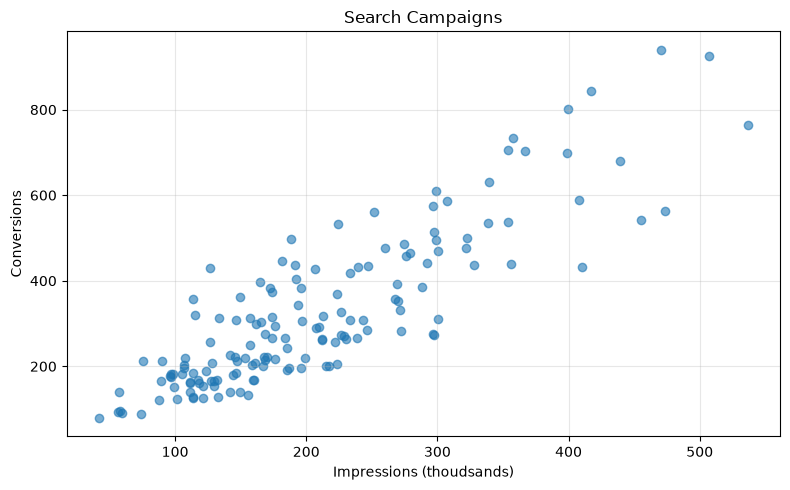

In [17]:
plt.figure(figsize=(8,5))
plt.scatter(search['impressions_k'],
            search['conversions'], color='tab:blue', alpha=.6)
plt.title('Search Campaigns')
plt.xlabel('Impressions (thoudsands)')
plt.ylabel('Conversions')
plt.grid(True, alpha=.3) # alpha is degree of transparency - 0 is see-through, 1 is 100% filled
plt.tight_layout() # Remove unnecessary white space
plt.show() # Print graph to notebook cell 

In [8]:
model = sm.ols('conversions ~ impressions_k', data=search).fit()

In [9]:
model.params

Intercept        5.039835
impressions_k    1.540643
dtype: float64

In [18]:
print('Expected impressions per one conversions:', 1000/model.params.values[1])
print('Expected conversions per 100,000 impressions:',
      model.params.values[0]+model.params.values[1]*100)

Expected impressions per one conversions: 649.0797692508253
Expected conversions per 100,000 impressions: 159.10410330818624


In [15]:
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            conversions   R-squared:                       0.749
Model:                            OLS   Adj. R-squared:                  0.747
Method:                 Least Squares   F-statistic:                     444.9
Date:                Tue, 03 Nov 2026   Prob (F-statistic):           1.38e-46
Time:                        14:58:28   Log-Likelihood:                -893.25
No. Observations:                 151   AIC:                             1790.
Df Residuals:                     149   BIC:                             1797.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         5.0398     16.835      0.299      0.765     -28.225      38.305
impressions_k     1.5406      0.073     21.092      0.000       1.396       1.685
==============================================================================
Omnibus:                        3.102   Durbin-Watson:                   1.357
Prob(Omnibus):                  0.212   Jarque-Bera (JB):                3.114
Skew:                           0.342   Prob(JB):                        0.211
Kurtosis:                       2.837   Cond. No.                         528.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [19]:
model.fittedvalues

1      311.251813
5      207.843875
7      346.913069
10     354.519222
12     353.926074
          ...    
427    556.332629
431    272.627900
434    730.081690
437    461.741790
438    295.614289
Length: 151, dtype: float64

In [22]:
model.resid # First campaign is negative so it falls short

1      -91.251813
5      -40.843875
7      -90.913069
10     -81.519222
12     -26.926074
          ...    
427    177.667371
431    100.372100
434    209.918310
437    112.258210
438    201.385711
Length: 151, dtype: float64

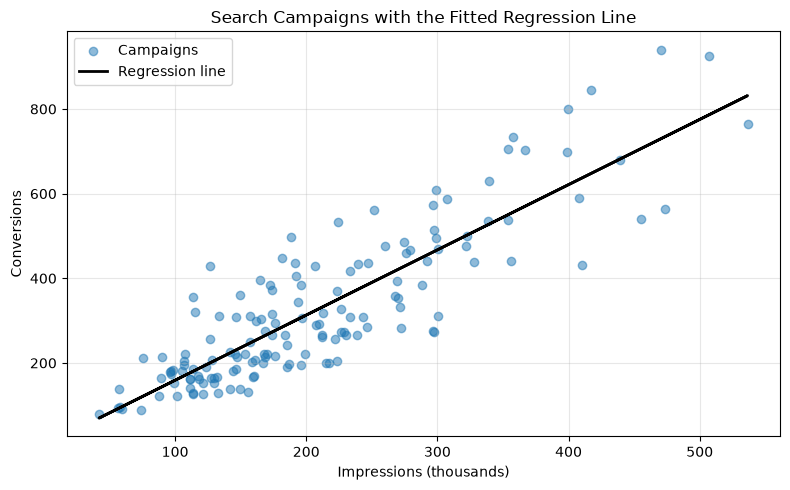

In [28]:
search['fitted_values'] = model.fittedvalues
line_data = search.sort_values('impressions_k')

plt.figure(figsize=(8,5))
plt.scatter(search['impressions_k'],
            search['conversions'], color='tab:blue', alpha=.5, label='Campaigns')
plt.plot(search['impressions_k'], search['fitted_values'], color='black', linewidth=2, label='Regression line')
plt.title('Search Campaigns with the Fitted Regression Line')
plt.xlabel('Impressions (thousands)')
plt.ylabel('Conversions')
plt.legend()
plt.grid(True, alpha=.3)
plt.tight_layout()
plt.show()

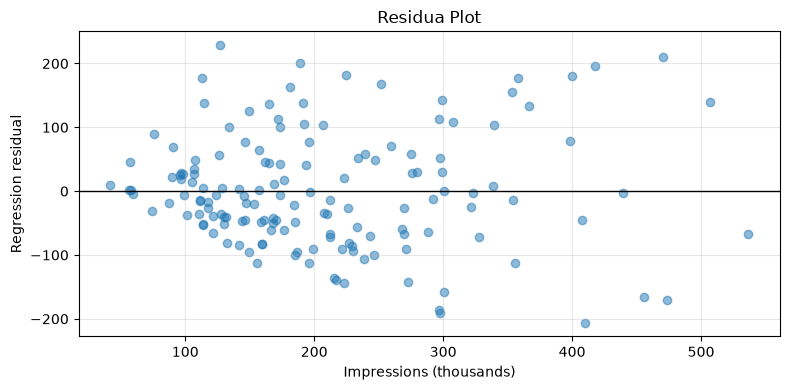

In [31]:
search['residual'] = model.resid
plt.figure(figsize=(8, 4))
plt.scatter(search['impressions_k'], search['residual'], color='tab:blue', alpha=.5)
plt.axhline(0, color='black', linewidth=1)
plt.title('Residua Plot')
plt.xlabel('Impressions (thousands)')
plt.ylabel('Regression residual')
plt.grid(True, alpha=.3)
plt.tight_layout()
plt.show()